# Build and compare SVM35 and Fusion SVM

Train two new support vector machine (SVM) models. Both use a radial basis function (RBF) kernel.

- **SVM35:** Scale the 35 acoustic features from the final E1 model. Use `C=1`.
- **Fusion SVM:** Use the same 35 acoustic features and add Whisper embedding.

## 1. Set the data path and run settings

Run this notebook from the project folder.
For Google Drive, set `USE_GOOGLE_DRIVE=True` and set `PROJECT_ROOT` to your project folder.
Store the source Parquet files in these folders under `PROJECT_ROOT`:

- `data/cv_subset/`
- `data/speechocean_subset/`
- `data/saa_subset/`
- `data/mnsc_subset/`

Each folder must contain `part-*.parquet` files.
Keep the training, validation, and test splits stored in these files.

Make sure the project contains these files:

- The source Parquet audio files.
- `scripts/cv_utils.py`.
- `scripts/svm35_fusion_data.py`.

Whisper uses the GPU. Its weights download automatically when needed.
The default GPU settings are for an RTX 4090.
SVM training and PCA use the CPU.

Set `REBUILD_FEATURES=True` only to extract features again. Keep the existing speaker splits.


In [16]:
# Install these packages if necessary. Then restart the kernel.
# The existing audioenv already has these packages.
# %pip -q install "transformers>=4.56,<5" torch librosa numpy pandas pyarrow soundfile soxr scikit-learn matplotlib joblib

from pathlib import Path
import sys
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/Singlish')
else:
    PROJECT_ROOT = Path.cwd()

PROJECT_ROOT = PROJECT_ROOT.resolve()
sys.path.insert(0, str(PROJECT_ROOT))
DATA_ROOT = PROJECT_ROOT / 'data'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'svm35_fusion_comparison_upstream'
CACHE_DIR = OUTPUT_DIR / 'feature_cache'
CHART_DIR = OUTPUT_DIR / 'charts'
LEGACY_E1_DIR = PROJECT_ROOT / 'outputs' / 'e1_feature_study_accent_3to6s_upstream'
LEGACY_WHISPER_PATH = PROJECT_ROOT / 'outputs' / 'e4_whisper_svm35_fusion_upstream' / 'whisper_embeddings.npz'
for folder in (OUTPUT_DIR, CACHE_DIR, CHART_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
REBUILD_FEATURES = False
WHISPER_MODEL = 'openai/whisper-base.en'
WHISPER_REVISION = 'main'  # Use a commit hash to select a fixed version of the weights.
WHISPER_BATCH_SIZE = 64
DECODE_WORKERS = 8
ACOUSTIC_WORKERS = 4
PCA_DIMENSIONS = 32
FUSION_C_VALUES = [0.01, 0.1, 1.0, 10.0]
CV_FOLDS = 3
BOOTSTRAP_REPEATS = 2000
RUN_SPEAKER_FOLDS = True
print('Upstream audio:', DATA_ROOT)
print('New results:', OUTPUT_DIR)

Upstream audio: /home/mh/nusproj/E1_Feature_Engineering/data
New results: /home/mh/nusproj/E1_Feature_Engineering/outputs/svm35_fusion_comparison_upstream


In [17]:
import json
from time import perf_counter
import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from scripts.svm35_fusion_data import (
    FINAL35, FEATURES91, META_COLUMNS, acoustic_features, whisper_features,
    load_dataset, digest, file_hash, write_json)

MODEL_NAMES = ('SVM35', 'Fusion SVM')
COLORS = {'SVM35': '#3274a1', 'Fusion SVM': '#e1812c'}

def save_chart(fig, name):
    fig.tight_layout()
    fig.savefig(CHART_DIR / name, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def model_bars(table, category, metric, title, order=None):
    values = table.pivot(index=category, columns='model', values=metric)
    values = values.reindex(table[category].drop_duplicates() if order is None else order)
    fig, ax = plt.subplots(figsize=(10, 4))
    x = np.arange(len(values))
    for offset, name in zip([-0.18, 0.18], MODEL_NAMES):
        bars = ax.bar(x + offset, 100 * values[name], 0.36, label=name, color=COLORS[name])
        ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)
    ax.set(xticks=x, xticklabels=values.index, ylim=(0, 104), title=title,
           ylabel=metric.replace('_', ' ').capitalize() + ' (%)')
    ax.legend(loc='lower right')
    return fig, ax

print('numpy:', np.__version__, '| librosa:', librosa.__version__, '| sklearn:', sklearn.__version__)

numpy: 2.5.3 | librosa: 1.0.0 | sklearn: 1.9.1


## 2. Load the data and keep the source speaker splits

Use `load_accent_data` to load the encoded FLAC audio.
Do not apply extra silence removal, normalization, resampling, padding, or truncation to the waveforms.
Keep the source `train`, `val`, and `test` assignments. Rename `val` to `validation`.
Identify each speaker by `(source, speaker_id)`.

Keep Common Voice Singaporean clips out of all main training, selection, fold, and test steps.
Save a record of the dataset. Check this record to prevent the use of different datasets in the same study folder.


In [18]:
clips, ood_clips = load_dataset(DATA_ROOT)
clip_ids = clips.index.to_numpy(dtype=str)
labels = clips['label'].to_numpy(dtype=np.int64)
groups = clips['speaker_group'].to_numpy(dtype=str)
split_names = clips['split'].to_numpy()
train_idx = np.flatnonzero(split_names == 'train')
val_idx = np.flatnonzero(split_names == 'validation')
test_idx = np.flatnonzero(split_names == 'test')
development_idx = np.concatenate([train_idx, val_idx])
snapshot = clips[META_COLUMNS]
dataset_id = digest(snapshot.reset_index().to_dict(orient='records'))
identity_path = OUTPUT_DIR / 'dataset_identity.json'
if identity_path.exists():
    previous_id = json.loads(identity_path.read_text())['dataset_id']
    if previous_id != dataset_id:
        raise ValueError('Dataset/splits changed. Choose a new OUTPUT_DIR to preserve prior results.')
write_json(identity_path, {'dataset_id': dataset_id})
snapshot.to_csv(OUTPUT_DIR / 'speaker_splits.csv')
ood_clips[META_COLUMNS].to_csv(OUTPUT_DIR / 'reserved_ood_clips.csv')
print('Main clips:', len(clips), '| reserved OOD:', len(ood_clips), '| speaker overlap: 0')
split_summary = clips.groupby(['split', 'label']).agg(clips=('label', 'size'), speakers=('speaker_group', 'nunique'))
display(split_summary)

Main clips: 11486 | reserved OOD: 554 | speaker overlap: 0


clips  speakers
split      label                 
test       0        980       529
           1        756       155
train      0       4519      2507
           1       3489       727
validation 0        987       537
           1        755       150

## 3. Load cached features or extract them from audio

Look for acoustic features in this order:

1. This notebook's cache.
2. Valid E1 caches with 39 or 91 features.
3. Source audio.

Look for Whisper features in this order:

1. This notebook's cache.
2. Valid E4 embeddings.
3. Source audio.



In [19]:
feature_started = perf_counter()
X91, acoustic_provenance = acoustic_features(clips, CACHE_DIR, LEGACY_E1_DIR,
    rebuild=REBUILD_FEATURES, workers=ACOUSTIC_WORKERS)
selected_columns = [FEATURES91.index(name) for name in FINAL35]
A = X91[:, selected_columns].astype(np.float32)
W, whisper_provenance = whisper_features(clips, CACHE_DIR, LEGACY_WHISPER_PATH,
    model_name=WHISPER_MODEL, revision=WHISPER_REVISION, batch_size=WHISPER_BATCH_SIZE,
    workers=DECODE_WORKERS, rebuild=REBUILD_FEATURES)
assert A.shape == (len(clips), 35) and W.shape[0] == len(clips)
assert np.isfinite(A).all() and np.isfinite(W).all()
# Build each model's inputs once. Keep the same column order for every fit.
inputs = {'SVM35': A, 'Fusion SVM': np.column_stack((A, W))}
del X91
feature_seconds = perf_counter() - feature_started
write_json(OUTPUT_DIR / 'feature_provenance.json',
    {'acoustic': acoustic_provenance, 'whisper': whisper_provenance,
     'feature_preparation_seconds': feature_seconds})
display(pd.DataFrame({'position': np.arange(1, 36), 'E1_column': selected_columns, 'feature': FINAL35}))
print('Acoustic:', A.shape, '| Whisper:', W.shape, '| preparation seconds:', round(feature_seconds, 2))

Reusing E1 acoustic cache: /home/mh/nusproj/E1_Feature_Engineering/outputs/e1_feature_study_accent_3to6s_upstream
Whisper cache unavailable/incompatible: /home/mh/nusproj/E1_Feature_Engineering/outputs/svm35_fusion_comparison_upstream/feature_cache/whisper_673881aab94ff816cc9b3357a23c40699d90de1e9e8c4482a00c51b9dad189c1.npz [Errno 2] No such file or directory: '/home/mh/nusproj/E1_Feature_Engineering/outputs/svm35_fusion_comparison_upstream/feature_cache/whisper_673881aab94ff816cc9b3357a23c40699d90de1e9e8c4482a00c51b9dad189c1.npz'
Reusing Whisper cache: /home/mh/nusproj/E1_Feature_Engineering/outputs/e4_whisper_svm35_fusion_upstream/whisper_embeddings.npz


,position,E1_column,feature
0,1,78,mfcc_delta_delta_1_std
1,2,5,mfcc_6_mean
2,3,14,mfcc_2_std
3,4,33,spectral_rolloff_mean
4,5,82,mfcc_delta_delta_5_std
5,6,35,zcr_mean
6,7,36,zcr_std
7,8,10,mfcc_11_mean
8,9,3,mfcc_4_mean
9,10,65,mfcc_delta_delta_1_mean


Acoustic: (11486, 35) | Whisper: (11486, 512) | preparation seconds: 4.67


## 4. Define new model pipelines

For SVM35, apply `StandardScaler`, then `SVC` with these settings:
`kernel=rbf`, `C=1`, `gamma=scale`, and `class_weight=balanced`.

For Fusion SVM:

1. Scale the acoustic features and Whisper features separately.
2. Apply PCA to the Whisper features.
3. Scale the PCA components.
4. Divide each feature group by the square root of its feature count.
5. Combine the two groups and apply the SVM.

The default fusion model has **35 + 32 = 67 inputs** after these steps.

Fit the scaling and PCA steps again for each model fit.
Use training rows for validation models. Use only the training speakers within each fold.
Use training and validation rows for the final models.
Saved pipelines contain all these steps and accept raw feature values.
They do not need functions or classes defined in this notebook.
Neither model converts decision scores to probabilities. Both use a decision threshold of zero.


In [20]:
def make_model(name, fit_rows, c_value):
    classifier = SVC(kernel='rbf', C=c_value, gamma='scale', class_weight='balanced',
                     random_state=RANDOM_SEED, cache_size=2048)
    if name == 'SVM35':
        return Pipeline([('preprocess', StandardScaler()), ('classifier', classifier)])
    dimensions = min(PCA_DIMENSIONS, len(fit_rows) - 1, W.shape[1])
    if dimensions < 2:
        raise ValueError('Too few fitting rows for Whisper PCA.')
    whisper_pipeline = Pipeline([('scale', StandardScaler()),
        ('pca', PCA(n_components=dimensions, random_state=RANDOM_SEED)),
        ('component_scale', StandardScaler())])
    acoustic_count = A.shape[1]
    preprocess = ColumnTransformer([
        ('acoustic', StandardScaler(), list(range(acoustic_count))),
        ('whisper', whisper_pipeline, list(range(acoustic_count, acoustic_count + W.shape[1])))],
        transformer_weights={'acoustic': 1 / np.sqrt(acoustic_count), 'whisper': 1 / np.sqrt(dimensions)})
    return Pipeline([('preprocess', preprocess), ('classifier', classifier)])

def prediction_frame(model, name, rows, stage, **extra):
    values = inputs[name][rows]
    pred = model.predict(values)
    scores = model.decision_function(values)
    return pd.DataFrame({'model': name, 'stage': stage, 'clip_id': clip_ids[rows],
        'speaker_group': groups[rows], 'source': clips.iloc[rows]['source'].to_numpy(),
        'true_label': labels[rows], 'prediction': pred, 'decision_score': scores, **extra})

def score_frame(frame, speaker_weighted=False):
    y, pred = frame.true_label.to_numpy(), frame.prediction.to_numpy()
    weights = (1 / frame.groupby('speaker_group')['clip_id'].transform('size').to_numpy()
               if speaker_weighted else None)
    cm = confusion_matrix(y, pred, labels=[0, 1], sample_weight=weights)
    return {'balanced_accuracy': float(balanced_accuracy_score(y, pred, sample_weight=weights)),
        'macro_f1': float(f1_score(y, pred, average='macro', sample_weight=weights, zero_division=0)),
        'sg_recall': float(cm[1, 1] / cm[1].sum()),
        'non_sg_fpr': float(cm[0, 1] / cm[0].sum()),
        'roc_auc': float(roc_auc_score(y, frame.decision_score, sample_weight=weights))}

def paired_speaker_interval(candidate, reference):
    candidate = candidate.set_index('clip_id', verify_integrity=True).sort_index()
    reference = reference.set_index('clip_id', verify_integrity=True).sort_index()
    if not candidate[['speaker_group', 'true_label']].equals(reference[['speaker_group', 'true_label']]):
        raise ValueError('Paired comparison must use identical rows, labels and speakers.')
    difference = (candidate.prediction == candidate.true_label).astype(float) - (reference.prediction == reference.true_label).astype(float)
    work = candidate[['speaker_group', 'true_label']].assign(difference=difference)
    speakers = work.groupby('speaker_group').agg(label=('true_label', 'first'), total=('difference', 'sum'), clips=('difference', 'size'))
    rng = np.random.default_rng(RANDOM_SEED)
    draws = np.zeros(BOOTSTRAP_REPEATS)
    estimate = 0.
    for label in [0, 1]:
        part = speakers.loc[speakers.label == label]
        indices = rng.integers(0, len(part), size=(BOOTSTRAP_REPEATS, len(part)))
        values, counts = part.total.to_numpy(), part.clips.to_numpy()
        draws += 0.5 * values[indices].sum(axis=1) / counts[indices].sum(axis=1)
        estimate += 0.5 * values.sum() / counts.sum()
    low, high = np.quantile(draws, [0.025, 0.975])
    return {'gain_points': float(100 * estimate), 'low_points': float(100 * low), 'high_points': float(100 * high),
            'repeats': BOOTSTRAP_REPEATS, 'method': 'paired class-stratified whole-speaker bootstrap; clip-balanced accuracy'}

## 5. Train the models and select fusion C

Keep SVM35 at `C=1`, as in E1.
For fusion, select the C value with the highest validation balanced accuracy.
If scores are equal, select the highest macro-F1. If those scores are equal, select the smaller C.

SVM35 C= 1.0 | validation balanced accuracy: 0.9345
Fusion SVM C= 0.01 | validation balanced accuracy: 0.9073
Fusion SVM C= 0.1 | validation balanced accuracy: 0.9599
Fusion SVM C= 1.0 | validation balanced accuracy: 0.9765
Fusion SVM C= 10.0 | validation balanced accuracy: 0.9774


,model,C,balanced_accuracy,macro_f1,sg_recall,non_sg_fpr,roc_auc
0,SVM35,1.0,0.9345,0.9325,0.9430,0.0740,0.9817
1,Fusion SVM,10.0,0.9774,0.9767,0.9801,0.0253,0.9981


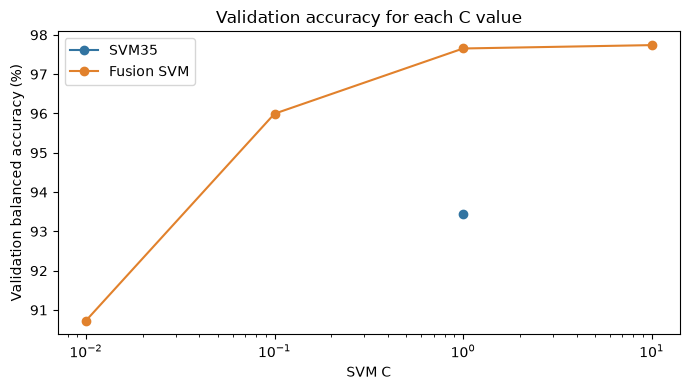

In [21]:
validation_models, validation_predictions = {}, {}
validation_trials, validation_rows = [], []
chosen_c = {}
for name in MODEL_NAMES:
    candidates = [1.] if name == 'SVM35' else FUSION_C_VALUES
    trials = []
    for c_value in candidates:
        started = perf_counter()
        model = make_model(name, train_idx, c_value)
        model.fit(inputs[name][train_idx], labels[train_idx])
        fit_seconds = perf_counter() - started
        frame = prediction_frame(model, name, val_idx, 'validation')
        row = {'model': name, 'C': c_value, 'fit_seconds': fit_seconds, **score_frame(frame)}
        validation_trials.append(row)
        trials.append((row, model, frame))
        print(name, 'C=', c_value, '| validation balanced accuracy:', round(row['balanced_accuracy'], 4), flush=True)
    row, model, frame = max(trials, key=lambda trial: (trial[0]['balanced_accuracy'], trial[0]['macro_f1'], -trial[0]['C']))
    chosen_c[name], validation_models[name], validation_predictions[name] = row['C'], model, frame
    validation_rows.append(row)
validation_table = pd.DataFrame(validation_rows).drop(columns='fit_seconds')
validation_trials = pd.DataFrame(validation_trials)
validation_trials.to_csv(OUTPUT_DIR / 'validation_C_trials.csv', index=False)
validation_table.to_csv(OUTPUT_DIR / 'validation_scores.csv', index=False)
pd.concat(validation_predictions.values()).to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False)
display(validation_table.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for name in MODEL_NAMES:
    part = validation_trials.query('model == @name')
    ax.plot(part.C, 100 * part.balanced_accuracy, 'o-', label=name, color=COLORS[name])
ax.set(xscale='log', xlabel='SVM C', ylabel='Validation balanced accuracy (%)', title='Validation accuracy for each C value')
ax.legend()
save_chart(fig, 'validation_C_curve.png')

## 6. Compare three folds with separate speakers

Combine training and validation data. Divide the speakers into three folds.
For each fold, train on the other speakers and evaluate on that fold's speakers.
Evaluate both models on the same clips. Each speaker is held out once.
Fit all scaling, PCA, and SVM steps again within each fold.
Show balanced accuracy and macro-F1 for each fold and for all fold predictions combined.
Do not use the main test set in these fits.

Finished fold 1 SVM35
Finished fold 1 Fusion SVM
Finished fold 2 SVM35
Finished fold 2 Fusion SVM
Finished fold 3 SVM35
Finished fold 3 Fusion SVM


,fold,model,fit_and_score_seconds,balanced_accuracy,macro_f1,sg_recall,non_sg_fpr,roc_auc
0,1,SVM35,1.0221,0.9512,0.9495,0.9590,0.0567,0.9909
1,1,Fusion SVM,1.5050,0.9766,0.9768,0.9717,0.0185,0.9979
2,2,SVM35,0.9189,0.9342,0.9301,0.9604,0.0920,0.9835
3,2,Fusion SVM,1.3802,0.9754,0.9744,0.9802,0.0294,0.9976
4,3,SVM35,1.0789,0.9458,0.9431,0.9618,0.0703,0.9858
5,3,Fusion SVM,1.4816,0.9757,0.9759,0.9710,0.0196,0.9974


,model,balanced_accuracy,macro_f1,sg_recall,non_sg_fpr,roc_auc
0,SVM35,0.9437,0.9409,0.9604,0.0730,0.9866
1,Fusion SVM,0.9759,0.9757,0.9743,0.0225,0.9976


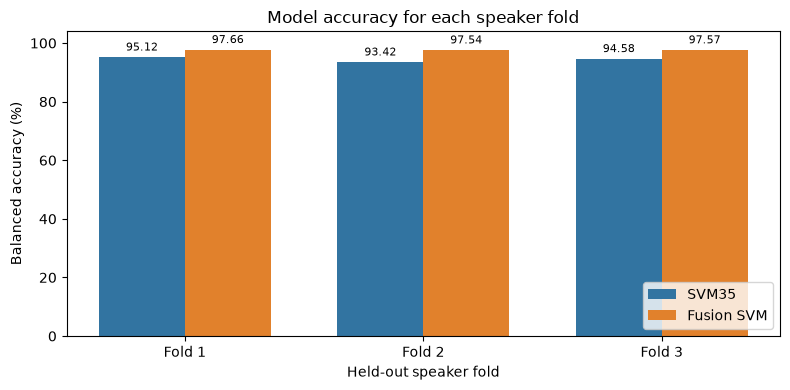

In [22]:
fold_predictions, fold_rows = [], []
if RUN_SPEAKER_FOLDS:
    splitter = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    for fold, (fit_local, held_local) in enumerate(splitter.split(A[development_idx], labels[development_idx], groups[development_idx]), start=1):
        fit_rows, held_rows = development_idx[fit_local], development_idx[held_local]
        assert not set(groups[fit_rows]) & set(groups[held_rows])
        assert not set(np.r_[fit_rows, held_rows]) & set(test_idx)
        assert set(labels[fit_rows]) == set(labels[held_rows]) == {0, 1}
        for name in MODEL_NAMES:
            started = perf_counter()
            model = make_model(name, fit_rows, chosen_c[name])
            model.fit(inputs[name][fit_rows], labels[fit_rows])
            frame = prediction_frame(model, name, held_rows, 'speaker fold', fold=fold)
            fold_predictions.append(frame)
            fold_rows.append({'fold': fold, 'model': name, 'fit_and_score_seconds': perf_counter() - started, **score_frame(frame)})
            print('Finished fold', fold, name, flush=True)
    fold_table = pd.DataFrame(fold_rows)
    fold_table.to_csv(OUTPUT_DIR / 'speaker_fold_scores.csv', index=False)
    fold_frame = pd.concat(fold_predictions, ignore_index=True)
    fold_frame.to_csv(OUTPUT_DIR / 'speaker_fold_predictions.csv', index=False)
    for name in MODEL_NAMES:
        held = fold_frame.loc[fold_frame.model == name]
        assert len(held) == len(development_idx) and held.clip_id.nunique() == len(development_idx)
    combined_fold_table = pd.DataFrame([{'model': name, **score_frame(fold_frame.loc[fold_frame.model == name])} for name in MODEL_NAMES])
    combined_fold_table.to_csv(OUTPUT_DIR / 'combined_fold_scores.csv', index=False)
    display(fold_table.round(4))
    display(combined_fold_table.round(4))
    fig, ax = model_bars(fold_table, 'fold', 'balanced_accuracy',
                         'Model accuracy for each speaker fold')
    ax.set_xlabel('Held-out speaker fold')
    save_chart(fig, 'speaker_folds.png')

## 7. Train and save the final models

Train new models on training rows followed by validation rows.
Keep SVM35 at `C=1`. Use the fusion C selected above.
Keep the 35 feature names and the PCA setting fixed.



In [23]:
final_models, final_fit_rows = {}, []
for name in MODEL_NAMES:
    started = perf_counter()
    model = make_model(name, development_idx, chosen_c[name])
    model.fit(inputs[name][development_idx], labels[development_idx])
    seconds = perf_counter() - started
    final_models[name] = model
    final_fit_rows.append({'model': name, 'fit_seconds': seconds})
    filename = 'svm_35.joblib' if name == 'SVM35' else 'fusion_svm.joblib'
    joblib.dump(model, OUTPUT_DIR / filename)
    print('Saved fresh model:', filename, '| fit seconds:', round(seconds, 2), flush=True)
fitted_pca = final_models['Fusion SVM'].named_steps['preprocess'].named_transformers_['whisper'].named_steps['pca']
model_metadata = {
    'dataset_id': dataset_id, 'feature_names': FINAL35, 'feature_columns_in_91': selected_columns,
    'svm35_input': 'raw 35 acoustic values in feature_names order',
    'fusion_input': 'column_stack([raw 35 acoustic values, raw Whisper embedding])',
    'whisper_model': WHISPER_MODEL, 'whisper_revision': WHISPER_REVISION,
    'whisper_width': int(W.shape[1]), 'whisper_pca_dimensions': int(fitted_pca.n_components_),
    'fusion_processed_width': 35 + int(fitted_pca.n_components_), 'chosen_C': chosen_c,
    'positive_label': 1, 'probability_calibration': False,
    'acoustic_provenance': acoustic_provenance, 'whisper_provenance': whisper_provenance,
    'helper_sha256': file_hash(PROJECT_ROOT / 'scripts/svm35_fusion_data.py'),
    'versions': {'numpy': np.__version__, 'librosa': librosa.__version__, 'sklearn': sklearn.__version__},
}
write_json(OUTPUT_DIR / 'model_metadata.json', model_metadata)
joblib.dump({'models': final_models, 'metadata': model_metadata}, OUTPUT_DIR / 'comparison_models.joblib')
pd.DataFrame(final_fit_rows).to_csv(OUTPUT_DIR / 'final_fit_times.csv', index=False)

Saved fresh model: svm_35.joblib | fit seconds: 1.11
Saved fresh model: fusion_svm.joblib | fit seconds: 1.32


## 8. Compare test scores, errors, ROC curves, and uncertainty

Evaluate both models on the same source test clips and speakers.
Use the default SVM decision threshold of zero.
Calculate area under the ROC curve (AUC) from decision scores, not probabilities.
Show false positives and false negatives.

Calculate the difference in balanced accuracy: **Fusion SVM minus SVM35**.
Use a paired speaker bootstrap to estimate a 95% uncertainty interval:

1. Sample speakers with replacement within each class.
2. Keep all clips from each sampled speaker together.
3. Use the same sample for both models.
4. Repeat the comparison and calculate the interval.

This interval estimates sampling uncertainty for these trained models, this dataset, and the earlier choices.
It does not remove selection bias.
E1 and E4 already examined this test set. These results do not give independent confirmation on new data.
Do not use test scores to select C, feature counts, or decision thresholds.


,model,balanced_accuracy,macro_f1,sg_recall,non_sg_fpr,roc_auc,false_positives,false_negatives,errors
0,SVM35,0.9440,0.9406,0.9656,0.0776,0.9875,76,26,102
1,Fusion SVM,0.9741,0.9720,0.9881,0.0398,0.9969,39,9,48


Fusion minus SVM35 balanced accuracy (percentage points): {'gain_points': 3.0120937263794407, 'low_points': 1.8980199202110006, 'high_points': 4.283851290556258, 'repeats': 2000, 'method': 'paired class-stratified whole-speaker bootstrap; clip-balanced accuracy'}


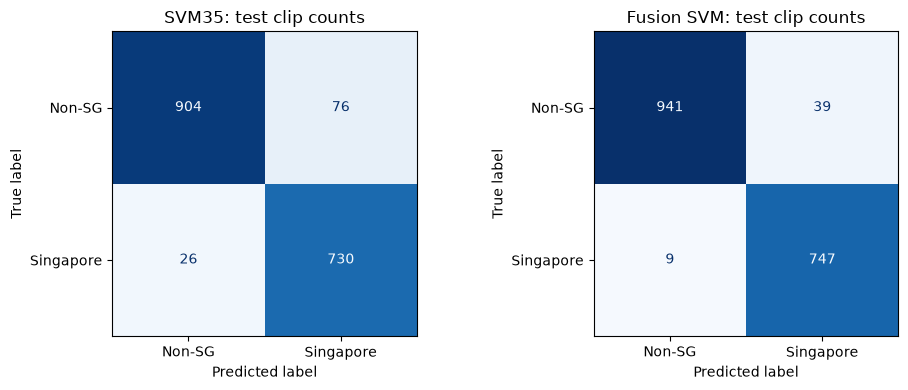

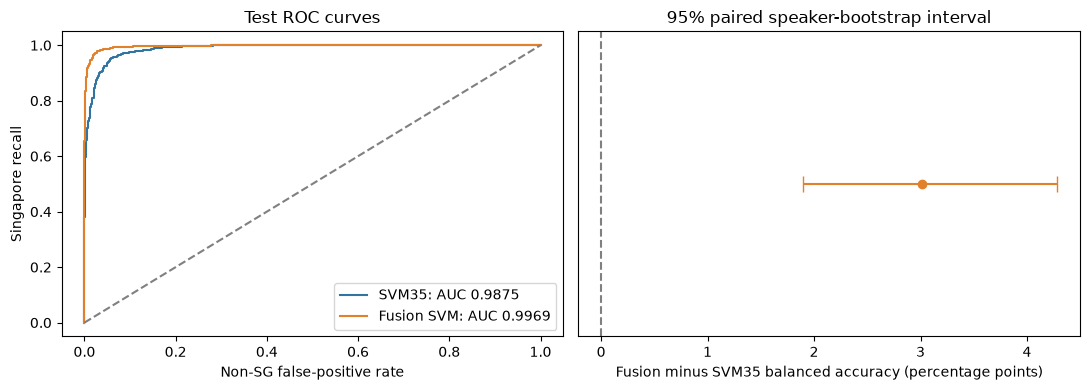

In [24]:
test_predictions, test_confusions = {}, {}
test_rows, timing_rows = [], []
for name in MODEL_NAMES:
    started = perf_counter()
    frame = prediction_frame(final_models[name], name, test_idx, 'test')
    timing_rows.append({'model': name, 'test_predict_and_score_seconds': perf_counter() - started,
                        'input': 'precomputed raw features; excludes audio/Whisper extraction'})
    test_predictions[name] = frame
    cm = confusion_matrix(frame.true_label, frame.prediction, labels=[0, 1])
    test_confusions[name] = cm
    test_rows.append({'model': name, **score_frame(frame), 'false_positives': int(cm[0, 1]),
        'false_negatives': int(cm[1, 0]), 'errors': int(cm[0, 1] + cm[1, 0])})
test_table = pd.DataFrame(test_rows)
test_table.to_csv(OUTPUT_DIR / 'test_scores.csv', index=False)
pd.concat(test_predictions.values()).to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
pd.DataFrame(timing_rows).to_csv(OUTPUT_DIR / 'test_prediction_times.csv', index=False)
paired_gain = paired_speaker_interval(test_predictions['Fusion SVM'], test_predictions['SVM35'])
write_json(OUTPUT_DIR / 'paired_test_gain.json', paired_gain)
display(test_table.round(4))
print('Fusion minus SVM35 balanced accuracy (percentage points):', paired_gain)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
maximum = max(cm.max() for cm in test_confusions.values())
for ax, name in zip(axes, MODEL_NAMES):
    ConfusionMatrixDisplay(test_confusions[name], display_labels=['Non-SG', 'Singapore']).plot(
        ax=ax, colorbar=False, cmap='Blues', im_kw={'vmin': 0, 'vmax': maximum})
    ax.set_title(name + ': test clip counts')
save_chart(fig, 'test_confusion_matrices.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in MODEL_NAMES:
    f = test_predictions[name]
    fpr, tpr, _ = roc_curve(f.true_label, f.decision_score)
    axes[0].plot(fpr, tpr, label=f"{name}: AUC {roc_auc_score(f.true_label, f.decision_score):.4f}", color=COLORS[name])
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(xlabel='Non-SG false-positive rate', ylabel='Singapore recall', title='Test ROC curves')
axes[0].legend()
axes[1].errorbar(paired_gain['gain_points'], 0,
    xerr=[[paired_gain['gain_points'] - paired_gain['low_points']], [paired_gain['high_points'] - paired_gain['gain_points']]],
    fmt='o', capsize=6, color=COLORS['Fusion SVM'])
axes[1].axvline(0, color='gray', linestyle='--')
axes[1].set(yticks=[], xlabel='Fusion minus SVM35 balanced accuracy (percentage points)', title='95% paired speaker-bootstrap interval')
save_chart(fig, 'test_roc_and_paired_gain.png')

## 9. Compare stages and scoring weights

Training scores evaluate the models on the same rows used to train them.
Validation scores use those same models on validation rows.
Test scores use new models trained on training and validation rows.
Combined fold scores use predictions made while each speaker was held out.
These stages use different training data. Do not read the score differences as the effect of training-set size alone.

Compare two scoring methods:

- **Equal clips:** Give each clip the same weight.
- **Equal speakers:** Give each clip weight `1 / number of clips from its speaker`.
  Each speaker then has the same total weight within its class.

Balanced accuracy gives both classes equal weight with either method.
The weights change the scores only. They do not change the models or predictions.


,stage,model,weighting,balanced_accuracy,macro_f1,sg_recall,non_sg_fpr,roc_auc
0,validation,SVM35,Equal clips,0.9345,0.9325,0.9430,0.0740,0.9817
1,validation,SVM35,Equal speakers,0.9468,0.9286,0.9423,0.0488,0.9891
2,test,SVM35,Equal clips,0.9440,0.9406,0.9656,0.0776,0.9875
3,test,SVM35,Equal speakers,0.9553,0.9376,0.9568,0.0461,0.9914
4,validation,Fusion SVM,Equal clips,0.9774,0.9767,0.9801,0.0253,0.9981
5,validation,Fusion SVM,Equal speakers,0.9840,0.9779,0.9827,0.0147,0.9989
6,test,Fusion SVM,Equal clips,0.9741,0.9720,0.9881,0.0398,0.9969
7,test,Fusion SVM,Equal speakers,0.9796,0.9658,0.9873,0.0281,0.9977


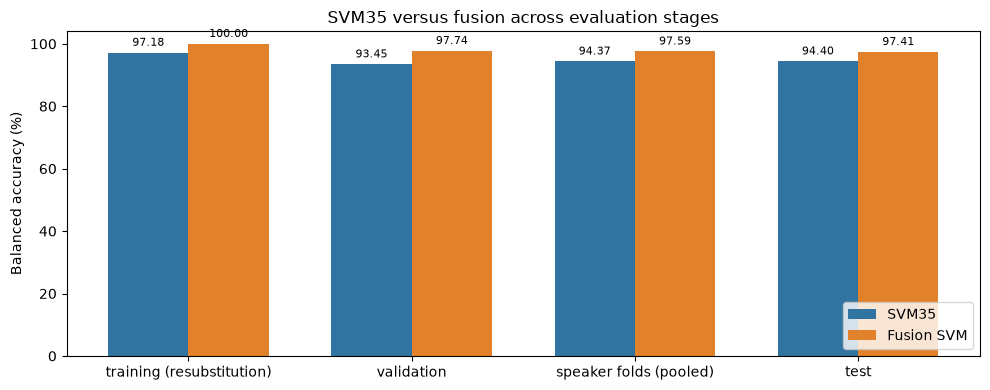

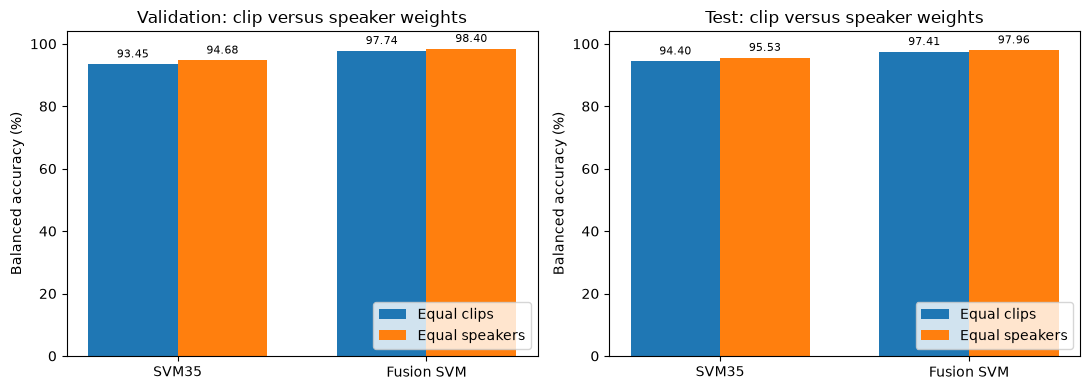

In [25]:
stage_rows, weight_rows = [], []
for name in MODEL_NAMES:
    train_frame = prediction_frame(validation_models[name], name, train_idx, 'training (resubstitution)')
    for stage, frame in [('training (resubstitution)', train_frame), ('validation', validation_predictions[name]), ('test', test_predictions[name])]:
        scores = score_frame(frame)
        stage_rows.append({'stage': stage, 'model': name, **scores})
        if stage != 'training (resubstitution)':
            weight_rows.append({'stage': stage, 'model': name, 'weighting': 'Equal clips', **scores})
            weight_rows.append({'stage': stage, 'model': name, 'weighting': 'Equal speakers',
                                **score_frame(frame, speaker_weighted=True)})
    if RUN_SPEAKER_FOLDS:
        stage_rows.append({'stage': 'speaker folds (pooled)', 'model': name,
            **score_frame(fold_frame.loc[fold_frame.model == name])})
stage_table = pd.DataFrame(stage_rows)
weight_table = pd.DataFrame(weight_rows)
stage_table.to_csv(OUTPUT_DIR / 'stage_comparison.csv', index=False)
weight_table.to_csv(OUTPUT_DIR / 'speaker_weight_comparison.csv', index=False)
display(weight_table.round(4))

stages = ['training (resubstitution)', 'validation'] + (['speaker folds (pooled)'] if RUN_SPEAKER_FOLDS else []) + ['test']
fig, ax = model_bars(stage_table, 'stage', 'balanced_accuracy',
                     'SVM35 versus fusion across evaluation stages', order=stages)
save_chart(fig, 'stage_comparison.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, stage in zip(axes, ['validation', 'test']):
    for offset, weighting in zip([-0.18, 0.18], ['Equal clips', 'Equal speakers']):
        values = weight_table.query('stage == @stage and weighting == @weighting').set_index('model').loc[list(MODEL_NAMES), 'balanced_accuracy'].to_numpy() * 100
        bars = ax.bar(np.arange(2) + offset, values, 0.36, label=weighting)
        ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)
    ax.set(xticks=[0, 1], xticklabels=list(MODEL_NAMES), ylim=(0, 104), ylabel='Balanced accuracy (%)', title=stage.title() + ': clip versus speaker weights')
    ax.legend(loc='lower right')
save_chart(fig, 'speaker_weight_comparison.png')

## 10. Check results for each data source

Compare accuracy and errors for each recording source.
Do not use these results to change a model.
**Singaporean is the positive class (label 1).**

- **False positive:** The model labels a non-Singaporean clip as Singaporean.
- **False negative:** The model labels a Singaporean clip as non-Singaporean.
- **Total errors:** Add false positives and false negatives.

Some sources contain only one class.
For these sources, show accuracy and class counts instead of balanced accuracy.
MNSC errors are false negatives. Errors from the non-Singaporean sources are false positives.
Data source and recording conditions are linked to the class labels.
These results cannot separate their effects from accent differences.


,model,source,clips,speakers,sg_clips,accuracy,false_positives,false_negatives,total_errors
0,SVM35,common_voice,808,503,0,0.9592,33,0,33
1,SVM35,mnsc,756,155,756,0.9656,0,26,26
2,SVM35,speech_accent_archive,50,8,0,0.8200,9,0,9
3,SVM35,speechocean762,122,18,0,0.7213,34,0,34
4,Fusion SVM,common_voice,808,503,0,0.9703,24,0,24
5,Fusion SVM,mnsc,756,155,756,0.9881,0,9,9
6,Fusion SVM,speech_accent_archive,50,8,0,0.9800,1,0,1
7,Fusion SVM,speechocean762,122,18,0,0.8852,14,0,14


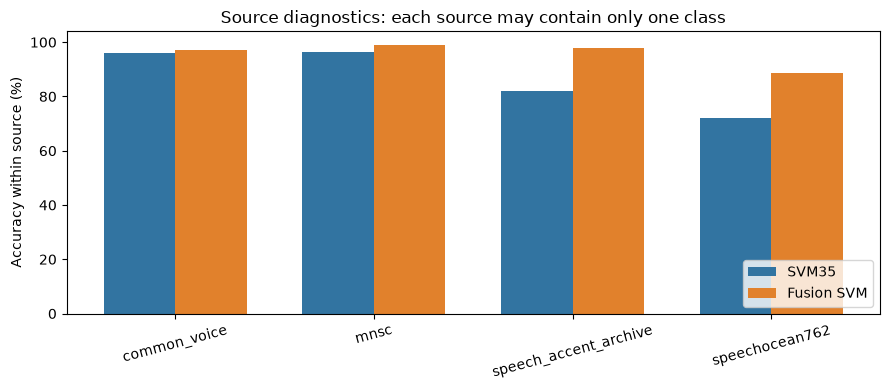

In [26]:
source_rows = []
for name in MODEL_NAMES:
    for source, frame in test_predictions[name].groupby('source'):
        false_positives = int((frame.true_label.eq(0) & frame.prediction.eq(1)).sum())
        false_negatives = int((frame.true_label.eq(1) & frame.prediction.eq(0)).sum())
        source_rows.append({'model': name, 'source': source, 'clips': len(frame),
            'speakers': frame.speaker_group.nunique(), 'sg_clips': int(frame.true_label.sum()),
            'accuracy': float(frame.prediction.eq(frame.true_label).mean()),
            'false_positives': false_positives, 'false_negatives': false_negatives,
            'total_errors': false_positives + false_negatives})
source_table = pd.DataFrame(source_rows)
source_table.to_csv(OUTPUT_DIR / 'test_source_diagnostics.csv', index=False)
display(source_table.round(4))
fig, ax = model_bars(source_table.sort_values('source'), 'source', 'accuracy',
                     'Source diagnostics: each source may contain only one class')
ax.set_ylabel('Accuracy within source (%)')
ax.tick_params(axis='x', labelrotation=15)
save_chart(fig, 'source_diagnostics.png')